# Chapter 22: Batches, small steps and budgets

Checks [chapter 22](../../book/22-batches-steps-and-budgets.md). Three small models, all NumPy in float64, seeded.
**Batches:** a model that is *linear in its weights* (`predictions = features @ weights`) trained by plain gradient steps on
squared error, which is the setting of `gradientStep_two_batches` and `linear_scaling_rule`. The control is a `tanh` model,
which is not linear in its weights. **Steps:** the polarizer of chapter 12 (a plate turned by `step_size` keeps
`cos(step_size)` of the amplitude, and `cos(step_size) >= 1 - step_size^2 / 2`), plus a step that keeps `1 - cost_rate * step_size`
as the linear-cost control. **Budget:** the loss above the floor `param_cost / param_count + data_cost / data_count` on a grid of
splits with `param_count * data_count` fixed. The control is unequal powers, where the proof does not apply.
These are measurements, not proofs: the proofs are in `BatchSize.lean`, `SmallSteps.lean` and `ComputeBudget.lean`.
Run every cell, top to bottom. A failed check stops the notebook.

In [1]:
import sys
sys.path.append("../part1")

import numpy as np
import matplotlib.pyplot as plt
from common import use_style, save_figure, report, NEAREST, VERTICAL, BOUND, MODEL, BEFORE

use_style()
SEED = 22


def take_gradient_step(features, labels, learning_rate, weights):
    # One step on squared error for a model linear in its weights: weights + learning_rate * features^T residual.
    residual = labels - features @ weights
    return weights + learning_rate * features.T @ residual


def get_correction(first_features, second_features, first_labels, learning_rate, weights):
    # The Lean correction: learning_rate^2 * second^T (second (first^T first_residual)).
    first_residual = first_labels - first_features @ weights
    return learning_rate ** 2 * second_features.T @ (second_features @ (first_features.T @ first_residual))

## Claim 1: the worked example of the batches (`gradientStep_two_batches` on one weight)

One weight at 0, features 1 and 1, labels 1 and 3. Prediction: at learning rate 0.1 two small steps give 0.39, one big
step gives 0.4, and the gap is `0.1^2 = 0.01`. At 0.2 it is 0.76, 0.8 and 0.04. A different answer would count against the chapter's
arithmetic. The gap is the big step minus the two steps.

In [2]:
for hand_rate in (0.1, 0.2):
    hand_weights = np.array([0.0])
    two_small = take_gradient_step(np.array([[1.0]]), np.array([3.0]),  hand_rate,
                                   take_gradient_step(np.array([[1.0]]), np.array([1.0]), hand_rate, hand_weights))
    one_big = hand_weights + hand_rate * (np.array([1.0]) * 1.0 + np.array([1.0]) * 3.0)
    hand_gap = float(one_big[0] - two_small[0])
    report(f"learning rate {hand_rate}: two small steps {two_small[0]:.2f}, one big step {one_big[0]:.2f}, gap {hand_gap:.4f}",
           abs(two_small[0] - (0.39 if hand_rate == 0.1 else 0.76)) < 1e-12 and abs(hand_gap - hand_rate ** 2) < 1e-12)

[PASS] learning rate 0.1: two small steps 0.39, one big step 0.40, gap 0.0100
[PASS] learning rate 0.2: two small steps 0.76, one big step 0.80, gap 0.0400


## Claim 2: two steps equal one big step minus `learning_rate^2` times the cross term, and the gap goes as `learning_rate^2`

**Prediction.** Take random batches of 5 examples each on 6 weights. For eight learning rates from 0.001 to 0.1 the gap
`one_big_step - two_steps` equals the Lean correction to rounding error (relative 1e-10). Because the identity is exact, the
gap is exactly `learning_rate^2` times a fixed vector, so a line through the points on log axes has slope 2 (accepted within 0.001).
Counting against the claim: any relative mismatch above 1e-10, or a slope away from 2.

**Control (the hypothesis broken).** The model `tanh(features @ weights)` is not linear in its weights. Same batches, the
Lean correction. The first step now also changes the second batch's slopes, which the formula ignores, so we expect the formula
to be wrong by a clear share of the gap: the check is that the relative mismatch is above 0.05, and the size is reported.
**Zero cross term.** If the second batch uses weights the first never touches (the cross kernel is zero), the gap is zero.

In [3]:
generator = np.random.default_rng(SEED)
WEIGHT_COUNT, BATCH_SIZE = 6, 5
first_features = generator.standard_normal((BATCH_SIZE, WEIGHT_COUNT))
second_features = generator.standard_normal((BATCH_SIZE, WEIGHT_COUNT))
first_labels = generator.standard_normal(BATCH_SIZE)
second_labels = generator.standard_normal(BATCH_SIZE)
start_weights = generator.standard_normal(WEIGHT_COUNT)
learning_rates = np.geomspace(0.001, 0.1, 8)


def measure_gap(features_one, features_two, labels_one, labels_two, learning_rate, weights):
    two_steps = take_gradient_step(features_two, labels_two, learning_rate,
                                   take_gradient_step(features_one, labels_one, learning_rate, weights))
    big_step = weights + learning_rate * (features_one.T @ (labels_one - features_one @ weights)
                                          + features_two.T @ (labels_two - features_two @ weights))
    return big_step - two_steps


gap_sizes, worst_mismatch = [], 0.0
for learning_rate in learning_rates:
    gap = measure_gap(first_features, second_features, first_labels, second_labels, learning_rate, start_weights)
    correction = get_correction(first_features, second_features, first_labels, learning_rate, start_weights)
    gap_sizes.append(np.linalg.norm(gap))
    worst_mismatch = max(worst_mismatch, np.linalg.norm(gap - correction) / np.linalg.norm(correction))
gap_sizes = np.array(gap_sizes)
fitted_slope = np.polyfit(np.log(learning_rates), np.log(gap_sizes), 1)[0]
report("gap equals the Lean correction at 8 learning rates", worst_mismatch < 1e-10, f"largest relative mismatch {worst_mismatch:.1e}")
report("the gap goes as learning_rate^2: slope on log axes is 2", abs(fitted_slope - 2.0) < 1e-3, f"fitted slope {fitted_slope:.6f}")


# Control: a model that is not linear in its weights.
def take_tanh_step(features, labels, learning_rate, weights):
    predictions = np.tanh(features @ weights)
    return weights + learning_rate * features.T @ ((labels - predictions) * (1.0 - predictions ** 2))


def measure_tanh_gap(learning_rate, weights):
    two_steps = take_tanh_step(second_features, second_labels, learning_rate,
                               take_tanh_step(first_features, first_labels, learning_rate, weights))
    def push(features, labels):
        predictions = np.tanh(features @ weights)
        return features.T @ ((labels - predictions) * (1.0 - predictions ** 2))
    return weights + learning_rate * (push(first_features, first_labels) + push(second_features, second_labels)) - two_steps


tanh_sizes, tanh_mismatch = [], []
tanh_start = 0.3 * start_weights
for learning_rate in learning_rates:
    tanh_gap = measure_tanh_gap(learning_rate, tanh_start)
    formula = get_correction(first_features, second_features, first_labels, learning_rate, tanh_start)
    tanh_sizes.append(np.linalg.norm(tanh_gap))
    tanh_mismatch.append(np.linalg.norm(tanh_gap - formula) / np.linalg.norm(tanh_gap))
tanh_sizes = np.array(tanh_sizes)
report("control: for a model not linear in its weights the Lean correction misses the gap",
       min(tanh_mismatch) > 0.05, f"relative mismatch from {min(tanh_mismatch):.2f} to {max(tanh_mismatch):.2f}")

# Zero cross term: batch one uses only the first three weights, batch two only the last three.
split_one = first_features.copy(); split_one[:, 3:] = 0.0
split_two = second_features.copy(); split_two[:, :3] = 0.0
cross_kernel_size = np.abs(split_two @ split_one.T).max()
zero_gap = np.linalg.norm(measure_gap(split_one, split_two, first_labels, second_labels, 0.1, start_weights))
report("zero cross kernel: two steps equal one big step", cross_kernel_size == 0.0 and zero_gap < 1e-14,
       f"cross kernel {cross_kernel_size:.1e}, gap {zero_gap:.1e}")

[PASS] gap equals the Lean correction at 8 learning rates  (largest relative mismatch 9.1e-13)
[PASS] the gap goes as learning_rate^2: slope on log axes is 2  (fitted slope 2.000000)
[PASS] control: for a model not linear in its weights the Lean correction misses the gap  (relative mismatch from 2.02 to 2.03)
[PASS] zero cross kernel: two steps equal one big step  (cross kernel 0.0e+00, gap 3.1e-16)


True

## Claim 3: the linear scaling rule (`linear_scaling_rule`)

**Prediction.** Batches of 8 examples, the push averaged over the batch. Two steps at `learning_rate` on batches of
`batch_size` equal one step on the `2 * batch_size` examples at `2 * learning_rate`, minus the Lean correction with the averaged
rate `learning_rate / batch_size`. The combined step is built independently here: stack the two batches and take the mean
gradient at twice the rate. It would fail if the doubling were not exact, or if the correction had the wrong rate.

In [4]:
BIG_BATCH = 8
stack_one = generator.standard_normal((BIG_BATCH, WEIGHT_COUNT))
stack_two = generator.standard_normal((BIG_BATCH, WEIGHT_COUNT))
labels_one = generator.standard_normal(BIG_BATCH)
labels_two = generator.standard_normal(BIG_BATCH)
scaling_weights = generator.standard_normal(WEIGHT_COUNT)
worst_scaling_mismatch, correction_sizes = 0.0, []
for learning_rate in (0.05, 0.5, 2.0):
    averaged_rate = learning_rate / BIG_BATCH
    two_steps = take_gradient_step(stack_two, labels_two, averaged_rate,
                                   take_gradient_step(stack_one, labels_one, averaged_rate, scaling_weights))
    stacked = np.vstack([stack_one, stack_two])
    stacked_labels = np.concatenate([labels_one, labels_two])
    mean_gradient = stacked.T @ (stacked_labels - stacked @ scaling_weights) / (2 * BIG_BATCH)
    one_step = scaling_weights + 2 * learning_rate * mean_gradient
    correction = get_correction(stack_one, stack_two, labels_one, averaged_rate, scaling_weights)
    correction_sizes.append(np.linalg.norm(correction))
    worst_scaling_mismatch = max(worst_scaling_mismatch, np.linalg.norm(two_steps - (one_step - correction)))
sizes_text = ", ".join(f"{size:.2e}" for size in correction_sizes)
report("two steps on batches of 8 equal one step on 16 at twice the rate, minus the correction",
       worst_scaling_mismatch < 1e-10, f"largest difference {worst_scaling_mismatch:.1e}, correction sizes {sizes_text}")

[PASS] two steps on batches of 8 equal one step on 16 at twice the rate, minus the correction  (largest difference 2.6e-15, correction sizes 7.52e-03, 7.52e-01, 1.20e+01)


True

## Figure: the gap against the learning rate

Written to `book/figures/22-gap-against-learning-rate.png`. Purple dots are the measured gap for the linear model. The green line is
`learning_rate^2` times the size of the Lean correction at learning rate 1, the **exact** law. Grey squares are the control: the `tanh`
model, whose gap is still small but is not given by the formula.

wrote book/figures/22-gap-against-learning-rate.png


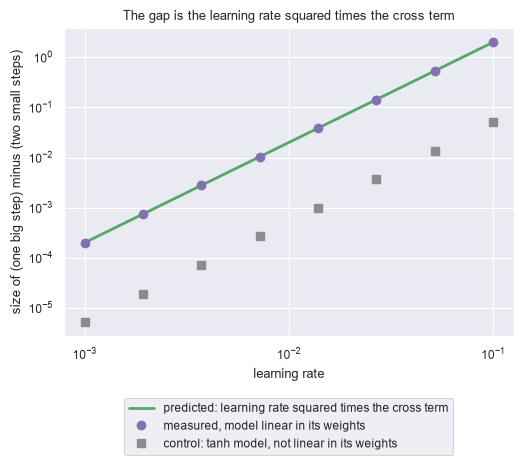

In [5]:
unit_correction = np.linalg.norm(get_correction(first_features, second_features, first_labels, 1.0, start_weights))
figure, axis = plt.subplots(figsize=(5.8, 4.0))
axis.loglog(learning_rates, unit_correction * learning_rates ** 2, color=BOUND, linewidth=2.0, label="predicted: learning rate squared times the cross term")
axis.loglog(learning_rates, gap_sizes, "o", color=MODEL, markersize=6, label="measured, model linear in its weights")
axis.loglog(learning_rates, tanh_sizes, "s", color=BEFORE, markersize=6, label="control: tanh model, not linear in its weights")
axis.set_xlabel("learning rate")
axis.set_ylabel("size of (one big step) minus (two small steps)")
axis.set_title("The gap is the learning rate squared times the cross term")
axis.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18))
save_figure(figure, "22-gap-against-learning-rate")
plt.show()

## Claim 4: many small steps keep more (`small_steps_keep`, `quadratic_cost_total`, `linear_cost_total`)

**Counting.** A step of size `step_size` costing `cost_rate * step_size^2`: the cost summed over `step_count` steps covering
`distance` is `cost_rate * distance^2 / step_count`. A cost of `cost_rate * step_size` sums to `cost_rate * distance`, which does not fall.
The sums are added up in a loop here, not read off the formula. At `cost_rate = 3`, `distance = 2`, `step_count = 10` the guarantee is `-0.2`
and at 100 steps it is `0.88`.

**Prediction for the polarizer.** `distance = pi / 2` (a crossed plate), `step_count` plates. Each plate keeps `cos(distance / step_count)`, which is at
least `1 - 0.5 * step_size^2`, so `cost_rate = 0.5`. The share kept is `cos(distance / step_count)^step_count`. It must be at least
`1 - cost_rate * distance^2 / step_count` for every `step_count` from 2 to 4096 (the hypothesis `cost_rate * step_size^2 <= 1` holds there).
The control: a step that keeps `1 - cost_rate * distance * step_size`, a cost in proportion to the step (matching the square law
at one step). Its kept share must stay far below the polarizer's at 4096 steps (a gap above 0.5), and below 0.5 itself (it tends to
`exp(-cost_rate * distance^2)`, about 0.29).

In [6]:
def sum_step_costs(step_count, distance, cost_rate, power):
    # Add up the cost of each of step_count steps, each of size distance / step_count.
    total = 0.0
    for _ in range(step_count):
        total += cost_rate * (distance / step_count) ** power
    return total


for step_count in (1, 10, 100):
    quadratic_total = sum_step_costs(step_count, 2.0, 3.0, 2)
    linear_total = sum_step_costs(step_count, 2.0, 3.0, 1)
    print(f"{step_count:4d} steps over distance 2, cost_rate 3: square-law total {quadratic_total:.4f}, linear total {linear_total:.4f}")
    report(f"{step_count} steps: square-law total is cost_rate*distance^2/steps, linear total is cost_rate*distance",
           abs(quadratic_total - 3.0 * 4.0 / step_count) < 1e-9 and abs(linear_total - 6.0) < 1e-9)
chapter_guarantees = [1 - 3.0 * 2.0 ** 2 / count for count in (10, 100)]
report("the chapter's check: guarantee -0.2 at 10 steps and 0.88 at 100", abs(chapter_guarantees[0] + 0.2) < 1e-12 and abs(chapter_guarantees[1] - 0.88) < 1e-12)

POLARIZER_DISTANCE, POLARIZER_COST_RATE = np.pi / 2, 0.5
step_counts = np.unique(np.round(np.geomspace(2, 4096, 40)).astype(int))
kept = np.cos(POLARIZER_DISTANCE / step_counts) ** step_counts
guarantee = 1 - POLARIZER_COST_RATE * POLARIZER_DISTANCE ** 2 / step_counts
hypothesis_holds = POLARIZER_COST_RATE * (POLARIZER_DISTANCE / step_counts) ** 2 <= 1
linear_kept = (1 - POLARIZER_COST_RATE * POLARIZER_DISTANCE * (POLARIZER_DISTANCE / step_counts)) ** step_counts
report("the small-steps hypothesis holds for every step count tried", bool(hypothesis_holds.all()))
report("polarizer: kept >= 1 - cost_rate*distance^2/step_count for 2 to 4096 plates",
       bool((kept >= guarantee - 1e-12).all()), f"smallest slack {float((kept - guarantee).min()):.2e}")
report("control: a cost in proportion to the step stays far below the polarizer at 4096 steps",
       linear_kept[-1] < 0.5 and kept[-1] - linear_kept[-1] > 0.5,
       f"polarizer keeps {kept[-1]:.4f}, linear-cost step keeps {linear_kept[-1]:.4f}")

   1 steps over distance 2, cost_rate 3: square-law total 12.0000, linear total 6.0000
[PASS] 1 steps: square-law total is cost_rate*distance^2/steps, linear total is cost_rate*distance
  10 steps over distance 2, cost_rate 3: square-law total 1.2000, linear total 6.0000
[PASS] 10 steps: square-law total is cost_rate*distance^2/steps, linear total is cost_rate*distance
 100 steps over distance 2, cost_rate 3: square-law total 0.1200, linear total 6.0000
[PASS] 100 steps: square-law total is cost_rate*distance^2/steps, linear total is cost_rate*distance
[PASS] the chapter's check: guarantee -0.2 at 10 steps and 0.88 at 100
[PASS] the small-steps hypothesis holds for every step count tried
[PASS] polarizer: kept >= 1 - cost_rate*distance^2/step_count for 2 to 4096 plates  (smallest slack 4.53e-08)
[PASS] control: a cost in proportion to the step stays far below the polarizer at 4096 steps  (polarizer keeps 0.9997, linear-cost step keeps 0.2912)


True

## Figure: what is lost against the number of steps

Written to `book/figures/22-steps-lost-against-count.png`. The share lost is one minus the share kept. Purple is the polarizer
(measured). Green is the bound `cost_rate * distance^2 / step_count` that `small_steps_keep` proves. Grey is the control with a cost
in proportion to the step: it levels off instead of falling.

wrote book/figures/22-steps-lost-against-count.png


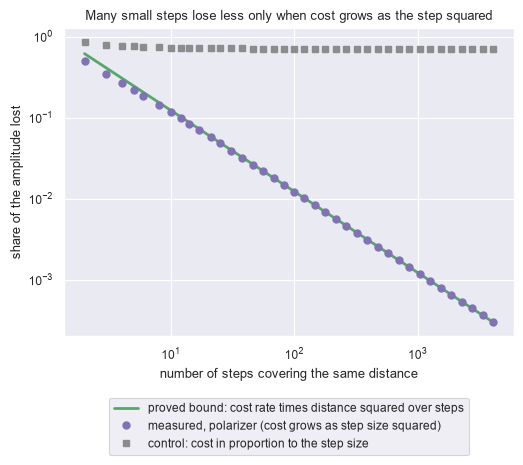

In [7]:
figure, axis = plt.subplots(figsize=(5.8, 4.0))
axis.loglog(step_counts, POLARIZER_COST_RATE * POLARIZER_DISTANCE ** 2 / step_counts, color=BOUND, linewidth=2.0, label="proved bound: cost rate times distance squared over steps")
axis.loglog(step_counts, 1 - kept, "o", color=MODEL, markersize=5, label="measured, polarizer (cost grows as step size squared)")
axis.loglog(step_counts, 1 - linear_kept, "s", color=BEFORE, markersize=5, label="control: cost in proportion to the step size")
axis.set_xlabel("number of steps covering the same distance")
axis.set_ylabel("share of the amplitude lost")
axis.set_title("Many small steps lose less only when cost grows as the step squared")
axis.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18))
save_figure(figure, "22-steps-lost-against-count")
plt.show()

## Claim 5: the balanced split is the best (`balanced_is_optimal`, `balanced_loss_sq`, `balanced_ratio`, `balanced_scale`)

**Hand numbers.** `param_cost = 8`, `data_cost = 2`, budget 100: loss above the floor 0.8 at (20, 5), 1.0 at (10, 10) and at (40, 2.5).

**Prediction.** For budgets 100, 400 and 10 000, scan 20 001 splits with `param_count` log-spaced over three decades around the balanced one.
The smallest measured loss is at the balanced split to within the grid step, and no scanned split beats it by more than rounding.
Its square is `4 * param_cost * data_cost / budget`. The ratio `param_count / data_count` at the best split is `param_cost / data_cost = 4` at
every budget. Scaling parameters and data by one factor keeps the two terms equal. So the best loss falls as one over the square root of the budget: the
slope of log best loss against log budget is -0.5. A scanned split that beats the balanced one, or a ratio that moves with the budget, would count against it.

**Control (hypothesis broken).** Unequal powers, `param_cost / param_count^0.34 + data_cost / data_count^0.28`, the fitted powers the chapter calls
measurements. The theorem does not apply. The measured best split is not the one with equal terms: we expect the equal-terms split
to lose to the best by a clear share (above 1 percent), and we report it.

In [8]:
PARAM_COST, DATA_COST = 8.0, 2.0
LOG_SPAN = 1.5          # the scan runs from 10^-1.5 to 10^1.5 times the balanced parameter count
GRID_POINTS = 20001


def get_loss_above_floor(param_count, data_count, param_power=1.0, data_power=1.0):
    return PARAM_COST / param_count ** param_power + DATA_COST / data_count ** data_power


for hand_params, hand_data, expected in ((20.0, 5.0, 0.8), (10.0, 10.0, 1.0), (40.0, 2.5, 1.0)):
    hand_loss = get_loss_above_floor(hand_params, hand_data)
    report(f"hand numbers: {hand_params:g} parameters and {hand_data:g} data give {hand_loss:.2f}", abs(hand_loss - expected) < 1e-12)

budgets = np.array([100.0, 400.0, 10000.0])
best_losses = []
for budget in budgets:
    balanced_params = np.sqrt(PARAM_COST * budget / DATA_COST)    # solves param_cost / P = data_cost * P / budget
    grid = balanced_params * 10 ** np.linspace(-LOG_SPAN, LOG_SPAN, GRID_POINTS)
    losses = get_loss_above_floor(grid, budget / grid)
    best_index = int(losses.argmin())
    best_params, best_loss = grid[best_index], losses[best_index]
    balanced_loss = get_loss_above_floor(balanced_params, budget / balanced_params)
    grid_step = balanced_params * 10 ** (LOG_SPAN * 2 / (GRID_POINTS - 1)) - balanced_params
    ratio = best_params / (budget / best_params)
    best_losses.append(best_loss)
    report(f"budget {budget:g}: the best scanned split is the balanced one ({balanced_params:.2f} parameters)",
           abs(best_params - balanced_params) <= 2 * grid_step and best_loss >= balanced_loss - 1e-12,
           f"best scanned {best_params:.2f}, best loss {best_loss:.5f}")
    report(f"budget {budget:g}: loss squared is 4*param_cost*data_cost/budget",
           abs(balanced_loss ** 2 - 4 * PARAM_COST * DATA_COST / budget) < 1e-12, f"{balanced_loss ** 2:.6f}")
    report(f"budget {budget:g}: parameters per datum at the best split is param_cost/data_cost",
           abs(ratio - PARAM_COST / DATA_COST) < 0.01, f"ratio {ratio:.4f}")
budget_slope = np.polyfit(np.log(budgets), np.log(best_losses), 1)[0]
report("the best loss falls as budget to the power -0.5", abs(budget_slope + 0.5) < 1e-3, f"fitted slope {budget_slope:.5f}")

scaled_terms = [PARAM_COST / (factor * 20.0) - DATA_COST / (factor * 5.0) for factor in (0.5, 2.0, 7.0)]
report("scaling both counts of (20, 5) by one factor keeps the two terms equal", max(abs(term) for term in scaled_terms) < 1e-12)
chapter_loss = get_loss_above_floor(40.0, 10.0)
report("the chapter's check: budget 400 balances at 40 parameters and 10 data, loss 0.4", abs(chapter_loss - 0.4) < 1e-12)

# Control: unequal powers.
PARAM_POWER, DATA_POWER = 0.34, 0.28
excess_shares = []
for budget in budgets:
    balanced_params = np.sqrt(PARAM_COST * budget / DATA_COST)     # equal terms only when both powers are one
    grid = balanced_params * 10 ** np.linspace(-LOG_SPAN, LOG_SPAN, GRID_POINTS)
    unequal = get_loss_above_floor(grid, budget / grid, PARAM_POWER, DATA_POWER)
    true_best_params = grid[int(unequal.argmin())]
    terms_at_best = (PARAM_COST / true_best_params ** PARAM_POWER) / (DATA_COST / (budget / true_best_params) ** DATA_POWER)
    balanced_unequal = get_loss_above_floor(balanced_params, budget / balanced_params, PARAM_POWER, DATA_POWER)
    excess_shares.append(balanced_unequal / unequal.min() - 1.0)
    print(f"control, budget {budget:g}: best split has {true_best_params:.2f} parameters, term ratio {terms_at_best:.3f}, equal-terms split loses {100 * excess_shares[-1]:.1f} percent more")
report("control: with unequal powers the equal-terms split is not the best", min(excess_shares) > 0.01,
       f"smallest excess {100 * min(excess_shares):.1f} percent")

[PASS] hand numbers: 20 parameters and 5 data give 0.80
[PASS] hand numbers: 10 parameters and 10 data give 1.00
[PASS] hand numbers: 40 parameters and 2.5 data give 1.00
[PASS] budget 100: the best scanned split is the balanced one (20.00 parameters)  (best scanned 20.00, best loss 0.80000)
[PASS] budget 100: loss squared is 4*param_cost*data_cost/budget  (0.640000)
[PASS] budget 100: parameters per datum at the best split is param_cost/data_cost  (ratio 4.0000)
[PASS] budget 400: the best scanned split is the balanced one (40.00 parameters)  (best scanned 40.00, best loss 0.40000)
[PASS] budget 400: loss squared is 4*param_cost*data_cost/budget  (0.160000)
[PASS] budget 400: parameters per datum at the best split is param_cost/data_cost  (ratio 4.0000)
[PASS] budget 10000: the best scanned split is the balanced one (200.00 parameters)  (best scanned 200.00, best loss 0.08000)
[PASS] budget 10000: loss squared is 4*param_cost*data_cost/budget  (0.006400)
[PASS] budget 10000: parameter

True

## Figure: the budget curve and its minimum

Written to `book/figures/22-budget-minimum.png`. Budget 100, `param_cost = 8`, `data_cost = 2`. The solid purple curve is the loss above the floor against the number
of parameters (data is `100 / parameters`). The dashed grey curves are its two terms. The green line marks the balanced split, 20 parameters,
where the terms cross. The dots mark the hand-example splits at 10, 20 and 40 parameters.

wrote book/figures/22-budget-minimum.png


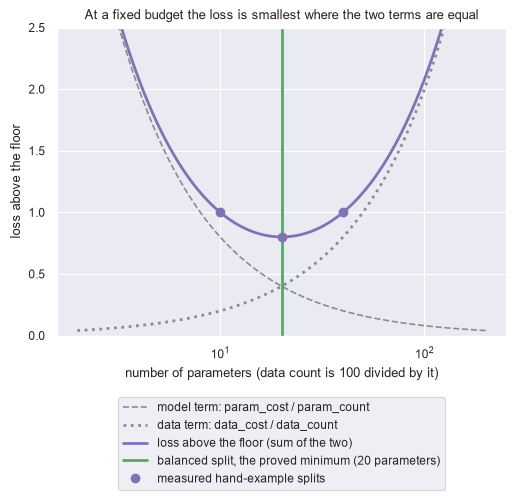

In [9]:
grid = np.geomspace(2.0, 200.0, 400)
total_curve = get_loss_above_floor(grid, 100.0 / grid)
figure, axis = plt.subplots(figsize=(5.8, 4.0))
axis.semilogx(grid, PARAM_COST / grid, "--", color=BEFORE, label="model term: param_cost / param_count")
axis.semilogx(grid, DATA_COST / (100.0 / grid), ":", color=BEFORE, linewidth=2.0, label="data term: data_cost / data_count")
axis.semilogx(grid, total_curve, color=MODEL, linewidth=2.0, label="loss above the floor (sum of the two)")
axis.axvline(20.0, color=BOUND, linewidth=2.0, label="balanced split, the proved minimum (20 parameters)")
axis.plot([10.0, 20.0, 40.0], [get_loss_above_floor(10.0, 10.0), get_loss_above_floor(20.0, 5.0), get_loss_above_floor(40.0, 2.5)],
          "o", color=MODEL, markersize=6, label="measured hand-example splits")
axis.set_ylim(0, 2.5)
axis.set_xlabel("number of parameters (data count is 100 divided by it)")
axis.set_ylabel("loss above the floor")
axis.set_title("At a fixed budget the loss is smallest where the two terms are equal")
axis.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18))
save_figure(figure, "22-budget-minimum")
plt.show()